# Chapter 19: The largest step

Checks [chapter 19](../../book/19-the-largest-step.md). The model is **linear in its weights**: a prediction is
`features @ weights`, with fixed sine and cosine features (and a constant) at fixed frequencies, so the kernel is
`features @ features.T` and its eigenvalues are the strengths. Where a claim is about chosen strengths (1, 2, 4, 9, or
the single strength 10 of the hand example) the features matrix is built from chosen singular values, which is still a
linear model; the cell says so. The loss is half the sum of squared residuals, so one step multiplies the error along a
direction of strength `strength` by `1 - learning_rate * strength`. Everything is NumPy in float64, seeded.
Gradient descent is run on the model and the error is projected on the kernel's eigenvectors; the formula is never
just plotted. These are measurements, not proofs: the proofs are in `EdgeOfStability.lean` and `Optimisers.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 19
TOLERANCE = 1e-9


def make_fourier_features(inputs, max_frequency):
    """A constant, then a sine and a cosine at each integer frequency up to max_frequency."""
    columns = [np.ones_like(inputs)]
    for frequency in range(1, max_frequency + 1):
        columns.append(np.sin(frequency * inputs))
        columns.append(np.cos(frequency * inputs))
    return np.stack(columns, axis=1)


def make_features_with_strengths(strengths, rng):
    """A square features matrix whose kernel has exactly these strengths: U diag(sqrt(strengths)) V^T."""
    count = len(strengths)
    left, _ = np.linalg.qr(rng.standard_normal((count, count)))
    right, _ = np.linalg.qr(rng.standard_normal((count, count)))
    return left @ np.diag(np.sqrt(strengths)) @ right.T


def run_descent(features, labels, start_weights, learning_rate, step_count):
    """Plain gradient descent on half the sum of squared residuals. Returns the residual after every step."""
    weights = start_weights.copy()
    history = [features @ weights - labels]
    for step in range(step_count):
        residual = features @ weights - labels
        weights = weights - learning_rate * (features.T @ residual)
        history.append(features @ weights - labels)
    return np.array(history)


def get_strengths(features):
    """Eigenvalues (ascending) and eigenvectors of the kernel, keeping only the nonzero strengths."""
    kernel = features @ features.T
    strengths, directions = np.linalg.eigh(kernel)
    keep = strengths > 1e-9 * strengths.max()
    return strengths[keep], directions[:, keep]


rng = np.random.default_rng(SEED)
POINT_COUNT = 14
inputs = np.sort(rng.uniform(-np.pi, np.pi, POINT_COUNT))
fourier_features = make_fourier_features(inputs, 3)
true_weights = rng.standard_normal(fourier_features.shape[1])
fourier_labels = fourier_features @ true_weights          # labels the model can fit, so the error can reach zero
fourier_strengths, fourier_directions = get_strengths(fourier_features)
strongest = fourier_strengths.max()
weakest = fourier_strengths.min()
print(f"Fourier model: {fourier_features.shape[0]} points, {fourier_features.shape[1]} weights, "
      f"strengths from {weakest:.3f} to {strongest:.3f}, edge 2 / strongest = {2 / strongest:.4f}")

Fourier model: 14 points, 7 weights, strengths from 1.032 to 17.278, edge 2 / strongest = 0.1158


## Claim 1: along a direction of strength `strength`, one step multiplies the error by `1 - learning_rate * strength`

This is chapter 18, which chapter 19 builds on. Start from zero weights, so the error is minus the labels. Run 30 steps
of gradient descent at `0.9 * 2 / strongest` (so the strongest direction has factor -0.8), project the error on every
eigenvector of the kernel, and compare with `(1 - learning_rate * strength) ** steps * start`.
Predicted: the largest gap is at rounding size, below `1e-9` of the start error, and no error is left outside the
directions with nonzero strength. Counted against the claim: any gap above that.

In [2]:
claim_rate = 0.9 * 2.0 / strongest
claim_steps = 30
history = run_descent(fourier_features, fourier_labels, np.zeros(fourier_features.shape[1]), claim_rate, claim_steps)
coefficients = fourier_directions.T @ history.T                       # one row per direction, one column per step
start_coefficients = coefficients[:, 0]
step_numbers = np.arange(claim_steps + 1)
predicted = (1 - claim_rate * fourier_strengths)[:, None] ** step_numbers[None, :] * start_coefficients[:, None]
largest_gap = float(np.abs(coefficients - predicted).max() / np.linalg.norm(history[0]))
outside = history - (fourier_directions @ coefficients).T
leftover = float(np.abs(outside).max() / np.linalg.norm(history[0]))
report("error along every direction equals (1 - rate * strength)^steps * start",
       largest_gap < TOLERANCE and leftover < TOLERANCE,
       f"largest gap {largest_gap:.1e} of the start error, error outside the directions {leftover:.1e}, "
       f"{len(fourier_strengths)} directions")

[PASS] error along every direction equals (1 - rate * strength)^steps * start  (largest gap 3.7e-16 of the start error, error outside the directions 6.4e-16, 7 directions)


True

## Claim 2: the hand example, strength 10, start error 8

A one-point model with feature `sqrt(10)` has kernel `[[10]]`, so strength 10. Weights start so that the error is 8.
Run the three learning rates of the chapter's table, 0.15, 0.20 and 0.25, for 3 steps.
Predicted: errors `8, -4, 2, -1` and `8, -8, 8, -8` and `8, -12, 18, -27`. After 3 steps at 0.25 the size is 27, and the
theorem `grows_past_edge` promises at least `8 * (1 + 3 * (rate - 2))` with `rate = 2.5`, which is 20.
Counted against the claim: any table entry off by more than rounding, or a size below 20.

In [3]:
hand_features = np.array([[np.sqrt(10.0)]])
hand_labels = np.array([0.0])
hand_start_weights = np.array([8.0 / np.sqrt(10.0)])                 # error = features @ weights - labels = 8
hand_table = {0.15: [8, -4, 2, -1], 0.20: [8, -8, 8, -8], 0.25: [8, -12, 18, -27]}
hand_runs = {}
for hand_rate, expected_errors in hand_table.items():
    hand_runs[hand_rate] = run_descent(hand_features, hand_labels, hand_start_weights, hand_rate, 3)[:, 0]
    report(f"learning rate {hand_rate}: errors match the table",
           np.allclose(hand_runs[hand_rate], expected_errors, atol=1e-9),
           "errors " + ", ".join(f"{value:.4f}" for value in hand_runs[hand_rate]))

promised_size = 8 * (1 + 3 * (0.25 * 10 - 2))
measured_size = abs(hand_runs[0.25][3])
report("past the edge, the size after 3 steps is at least 8 * (1 + 3 * (rate - 2))",
       measured_size >= promised_size - 1e-9,
       f"measured size {measured_size:.4f}, promised at least {promised_size:.4f}")

[PASS] learning rate 0.15: errors match the table  (errors 8.0000, -4.0000, 2.0000, -1.0000)
[PASS] learning rate 0.2: errors match the table  (errors 8.0000, -8.0000, 8.0000, -8.0000)
[PASS] learning rate 0.25: errors match the table  (errors 8.0000, -12.0000, 18.0000, -27.0000)
[PASS] past the edge, the size after 3 steps is at least 8 * (1 + 3 * (rate - 2))  (measured size 27.0000, promised at least 20.0000)


True

## Claim 3: the factor is below one in size exactly when `learning_rate * strength` is between 0 and 2

On the strongest direction of the Fourier model, take `learning_rate * strongest` at 31 values from 0 to 3. For each,
take ONE step of gradient descent on the model from an error that lies along that direction, and measure the ratio of
the error after the step to the error before. Predicted: the measured ratio is `1 - rate * strength` to rounding error;
its size is below one for every value strictly between 0 and 2 and at least one for every value at or past 2.
The control is the value 1, where the factor is 0 and the error must vanish in one step. Counted against the claim:
a ratio off the line, or a size below one outside the band.

In [4]:
strongest_direction = fourier_directions[:, -1]
direction_weights = np.linalg.pinv(fourier_features) @ strongest_direction     # an error exactly along that direction
zero_labels = np.zeros(POINT_COUNT)
rates_times_strength = np.linspace(0.0, 3.0, 31)
measured_factors = []
for rate_times_strength in rates_times_strength:
    one_step = run_descent(fourier_features, zero_labels, direction_weights, rate_times_strength / strongest, 1)
    before = float(strongest_direction @ one_step[0])
    after = float(strongest_direction @ one_step[1])
    measured_factors.append(after / before)
measured_factors = np.array(measured_factors)
formula_factors = 1 - rates_times_strength
line_gap = float(np.abs(measured_factors - formula_factors).max())
inside = (rates_times_strength > 0) & (rates_times_strength < 2)
size_below_one = np.abs(measured_factors) < 1 - 1e-9
band_agrees = bool(np.all(size_below_one[inside])) and not bool(np.any(size_below_one[~inside]))
cure_index = int(np.argmin(np.abs(rates_times_strength - 1.0)))
report("measured factor lies on 1 - rate, and its size is below one exactly inside 0 < rate < 2",
       line_gap < TOLERANCE and band_agrees,
       f"largest gap to the line {line_gap:.1e}, {int(inside.sum())} values inside the band")
report("control: at rate = 1 the error vanishes in one step",
       abs(measured_factors[cure_index]) < TOLERANCE,
       f"factor at rate 1 is {measured_factors[cure_index]:.1e}")

[PASS] measured factor lies on 1 - rate, and its size is below one exactly inside 0 < rate < 2  (largest gap to the line 6.7e-16, 19 values inside the band)
[PASS] control: at rate = 1 the error vanishes in one step  (factor at rate 1 is 5.4e-17)


True

### Figure: the factor against `learning_rate * strength`

The line is the factor, drawn from the formula; the dots are the ratios measured above from one step of gradient
descent on the model. The shaded band is where the size of the factor is below one.

wrote book/figures/19-factor-line.png

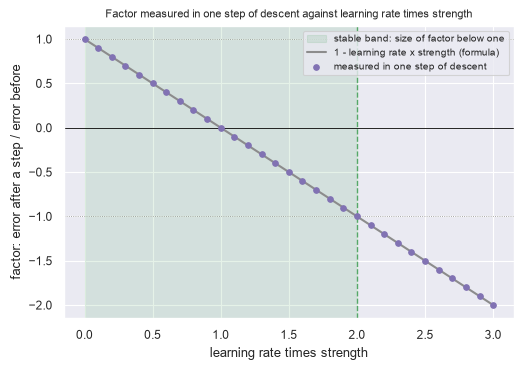

In [5]:
figure, axis = plt.subplots(figsize=(5.8, 3.8))
axis.axvspan(0, 2, color=BOUND, alpha=0.15, label="stable band: size of factor below one")
axis.plot(rates_times_strength, formula_factors, color=BEFORE, lw=1.5, label="1 - learning rate x strength (formula)")
axis.scatter(rates_times_strength, measured_factors, color=MODEL, s=16, zorder=3, label="measured in one step of descent")
axis.axhline(0, color="black", lw=0.6)
axis.axhline(1, color=BEFORE, lw=0.6, ls=":")
axis.axhline(-1, color=BEFORE, lw=0.6, ls=":")
axis.axvline(2, color=BOUND, lw=1.0, ls="--")
axis.set_xlabel("learning rate times strength")
axis.set_ylabel("factor: error after a step / error before")
axis.set_title("Factor measured in one step of descent against learning rate times strength", fontsize=8)
axis.legend(loc="upper right", fontsize=7)
save_figure(figure, "19-factor-line")
plt.show()

## Claim 4: the largest stable learning rate is `2 / strongest`

Run 300 steps of gradient descent on the whole Fourier model with `learning_rate = ratio * 2 / strongest` for ratios
0.5, 0.9, 0.99, 1.0, 1.01, 1.1 and 1.5. Predicted: the total error at the end is below the start for every ratio under
one and above it for every ratio over one; at ratio exactly one the error along the strongest direction keeps its
size (it only changes sign). Counted against the claim: a ratio under one with a larger error, a ratio over one with a
smaller error, or a size at ratio one that is not constant.

In [6]:
edge_ratios = [0.5, 0.9, 0.99, 1.0, 1.01, 1.1, 1.5]
edge_steps = 300
start_error = np.linalg.norm(fourier_labels)
for ratio in edge_ratios:
    edge_history = run_descent(fourier_features, fourier_labels, np.zeros(fourier_features.shape[1]),
                               ratio * 2.0 / strongest, edge_steps)
    final_error = float(np.linalg.norm(edge_history[-1]))
    strongest_sizes = np.abs(edge_history @ strongest_direction)
    below = ratio < 1
    if ratio == 1.0:
        size_change = float(strongest_sizes.max() / strongest_sizes.min())
        report("at the edge, the error along the strongest direction keeps its size",
               size_change < 1 + 1e-9, f"{edge_steps} steps, largest size over smallest size {size_change:.12f}")
    else:
        report(f"ratio {ratio}: final error {'below' if below else 'above'} the start",
               (final_error < start_error) == below,
               f"after {edge_steps} steps, final / start = {final_error / start_error:.3g}")

[PASS] ratio 0.5: final error below the start  (after 300 steps, final / start = 3.2e-10)
[PASS] ratio 0.9: final error below the start  (after 300 steps, final / start = 1.35e-16)
[PASS] ratio 0.99: final error below the start  (after 300 steps, final / start = 0.0019)
[PASS] at the edge, the error along the strongest direction keeps its size  (300 steps, largest size over smallest size 1.000000000000)
[PASS] ratio 1.01: final error above the start  (after 300 steps, final / start = 310)
[PASS] ratio 1.1: final error above the start  (after 300 steps, final / start = 4.63e+23)
[PASS] ratio 1.5: final error above the start  (after 300 steps, final / start = 1.66e+90)


### Figure: error against steps below, at and above the stability limit

The same model and the same start, three learning rates: half the limit `2 / strongest`, the limit itself, and 1.05 times
it. The vertical axis is the size of the error (the Euclidean norm of the residual), on a log scale. Every curve is
from gradient descent on the model.

wrote book/figures/19-edge-runs.png


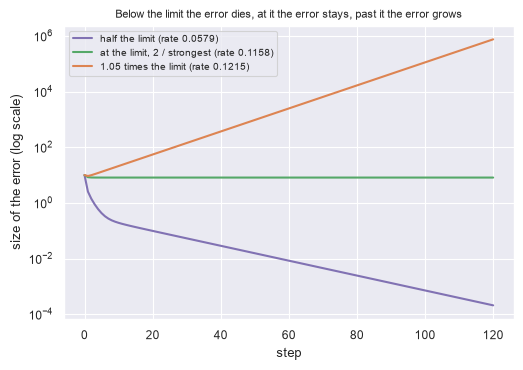

error after 120 steps over start error: 0.5 -> 2.09e-05, 1.0 -> 0.815, 1.05 -> 7.55e+04


In [7]:
figure_ratios = [(0.5, "half the limit", MODEL), (1.0, "at the limit, 2 / strongest", BOUND),
                 (1.05, "1.05 times the limit", VERTICAL)]
figure_steps = 120
figure, axis = plt.subplots(figsize=(5.8, 3.8))
figure_final = {}
for ratio, label, colour in figure_ratios:
    figure_history = run_descent(fourier_features, fourier_labels, np.zeros(fourier_features.shape[1]),
                                 ratio * 2.0 / strongest, figure_steps)
    sizes = np.linalg.norm(figure_history, axis=1)
    figure_final[ratio] = sizes[-1] / sizes[0]
    axis.plot(np.arange(figure_steps + 1), sizes, color=colour, lw=1.5,
              label=f"{label} (rate {ratio * 2.0 / strongest:.4f})")
axis.set_yscale("log")
axis.set_xlabel("step")
axis.set_ylabel("size of the error (log scale)")
axis.set_title("Below the limit the error dies, at it the error stays, past it the error grows", fontsize=8)
axis.legend(loc="upper left", fontsize=7)
save_figure(figure, "19-edge-runs")
plt.show()
print(f"error after {figure_steps} steps over start error: "
      + ", ".join(f"{ratio} -> {figure_final[ratio]:.3g}" for ratio in figure_final))

## Claim 5: past the edge, the error along a direction grows at least like `1 + steps * (rate - 2)`

On the one-point model of strength 10 and start error 8, with `rate` (learning rate times strength) 2.0, 2.25 and 2.5, run
25 steps. Predicted: the size of the error after `steps` steps is at least `8 * (1 + steps * (rate - 2))` for every step from 1 to 25.
Step 0 is left out of the margin, because the start error is 8 whatever the rate and the bound is 8 there. At rate 2.0 the bound is
8 at every step, so a margin of about 0 is expected there. Counted against the claim: any step where the size is smaller than that.

In [8]:
for rate_times_strength in (2.0, 2.25, 2.5):
    past_history = run_descent(hand_features, hand_labels, hand_start_weights, rate_times_strength / 10.0, 25)[:, 0]
    promised = 8 * (1 + np.arange(26) * (rate_times_strength - 2))
    margin = float((np.abs(past_history[1:]) - promised[1:]).min())          # step 0 excluded
    report(f"rate {rate_times_strength}: size stays at least 8 * (1 + steps * (rate - 2))",
           margin > -1e-9, f"smallest margin over steps 1 to 25 {margin:.3g}, size after 25 steps {abs(past_history[-1]):.4g}")

[PASS] rate 2.0: size stays at least 8 * (1 + steps * (rate - 2))  (smallest margin over steps 1 to 25 3.55e-15, size after 25 steps 8)
[PASS] rate 2.25: size stays at least 8 * (1 + steps * (rate - 2))  (smallest margin over steps 1 to 25 1.78e-15, size after 25 steps 2118)
[PASS] rate 2.5: size stays at least 8 * (1 + steps * (rate - 2))  (smallest margin over steps 1 to 25 1.78e-15, size after 25 steps 2.02e+05)


## Claim 6: the best step is `2 / (weakest + strongest)`, and the speed is `(strongest - weakest) / (strongest + weakest)`

Strengths 1, 2, 4 and 9, from a features matrix built from those singular values (a linear model with exactly that
kernel). Predicted: the best step is `2 / 10 = 0.2`; at that step the factors are 0.8, 0.6, 0.2 and -0.8; no factor is
above `8 / 10 = 0.8` in size; the weakest direction shrinks by exactly 0.8; and no other learning rate on a fine grid does
better than 0.8 in its worst direction. Counted against the claim: a factor of size above 0.8 at the best step, or a rate
on the grid whose worst factor is below 0.8. The cell also counts steps to shrink the error 100-fold at a small, the best
and a too-large step.

In [9]:
spread_strengths = np.array([1.0, 2.0, 4.0, 9.0])
spread_features = make_features_with_strengths(spread_strengths, np.random.default_rng(SEED + 1))
spread_labels = spread_features @ np.random.default_rng(SEED + 2).standard_normal(4)
measured_strengths, spread_directions = get_strengths(spread_features)
# By construction, cannot fail: the features were built from these singular values. Not counted as evidence.
print("[by construction, cannot fail] the built kernel has strengths "
      + ", ".join(f"{value:.6f}" for value in measured_strengths))

best_step = 2.0 / (measured_strengths.min() + measured_strengths.max())
promised_speed = (measured_strengths.max() - measured_strengths.min()) / (measured_strengths.max() + measured_strengths.min())
spread_history = run_descent(spread_features, spread_labels, np.zeros(4), best_step, 1)
start_coefficients = spread_directions.T @ spread_history[0]
after_coefficients = spread_directions.T @ spread_history[1]
measured_best_factors = after_coefficients / start_coefficients
report("best step is 0.2, every factor has size at most 0.8, and the weakest direction shrinks by exactly 0.8",
       abs(best_step - 0.2) < 1e-12 and np.abs(measured_best_factors).max() <= promised_speed + 1e-9
       and abs(measured_best_factors[0] - promised_speed) < 1e-9,
       "factors " + ", ".join(f"{value:.4f}" for value in measured_best_factors))

grid = np.linspace(0.005, 0.3, 1000)
def measure_worst_factor(rate):
    """Run one step of descent from a start error with every direction present; the worst measured factor."""
    one_step = run_descent(spread_features, spread_labels, np.zeros(4), rate, 1)
    return float(np.abs((spread_directions.T @ one_step[1]) / (spread_directions.T @ one_step[0])).max())


worst_factors = np.array([measure_worst_factor(rate) for rate in grid])
report("no learning rate on the grid has a worst factor below 0.8",
       worst_factors.min() >= promised_speed - 1e-9 and abs(grid[np.argmin(worst_factors)] - 0.2) < 1e-3,
       f"{len(grid)} rates, each one step of descent; smallest worst factor {worst_factors.min():.4f} at rate {grid[np.argmin(worst_factors)]:.4f}")


def count_steps_to_shrink(rate, shrink_by=100.0, step_limit=300):
    history = run_descent(spread_features, spread_labels, np.zeros(4), rate, step_limit)
    sizes = np.linalg.norm(history, axis=1)
    reached = np.nonzero(sizes <= sizes[0] / shrink_by)[0]
    return int(reached[0]) if len(reached) else None


step_counts = {rate: count_steps_to_shrink(rate) for rate in (0.05, 0.2, 0.25)}
print("steps to shrink the error 100-fold: " + ", ".join(f"rate {rate} -> {count}" for rate, count in step_counts.items()))
report("the best step needs fewer steps than a small step, and a step past 2 / strongest never gets there",
       step_counts[0.2] is not None and step_counts[0.05] is not None and step_counts[0.2] < step_counts[0.05]
       and step_counts[0.25] is None,
       f"best {step_counts[0.2]} steps, small {step_counts[0.05]} steps, too large {step_counts[0.25]}")

[by construction, cannot fail] the built kernel has strengths 1.000000, 2.000000, 4.000000, 9.000000
[PASS] best step is 0.2, every factor has size at most 0.8, and the weakest direction shrinks by exactly 0.8  (factors 0.8000, 0.6000, 0.2000, -0.8000)
[PASS] no learning rate on the grid has a worst factor below 0.8  (1000 rates, each one step of descent; smallest worst factor 0.8001 at rate 0.1999)
steps to shrink the error 100-fold: rate 0.05 -> 72, rate 0.2 -> 21, rate 0.25 -> None
[PASS] the best step needs fewer steps than a small step, and a step past 2 / strongest never gets there  (best 21 steps, small 72 steps, too large None)


True

### Figure: the size of every direction's factor at three learning rates

One bar per direction (strengths 1, 2, 4, 9), height the size of the factor measured in one step of gradient descent.
Predicted: at the small rate every bar is under one but the weakest is near one; at the best step the two end bars are
the tallest, both 0.8; at the too-large rate the strongest bar is above one.

wrote book/figures/19-many-directions.png


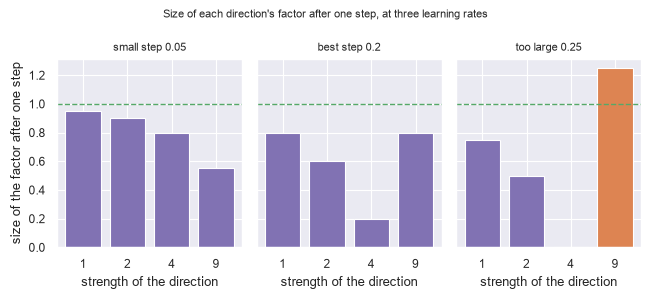

bar heights: rate 0.05: 0.950, 0.900, 0.800, 0.550; rate 0.2: 0.800, 0.600, 0.200, 0.800; rate 0.25: 0.750, 0.500, 0.000, 1.250


In [10]:
figure_rates = [(0.05, "small step 0.05"), (0.2, "best step 0.2"), (0.25, "too large 0.25")]
bar_sizes = {}
for rate, _ in figure_rates:
    one_step = run_descent(spread_features, spread_labels, np.zeros(4), rate, 1)
    bar_sizes[rate] = np.abs((spread_directions.T @ one_step[1]) / (spread_directions.T @ one_step[0]))
figure, axes = plt.subplots(1, 3, figsize=(6.6, 3.0), sharey=True)
bar_positions = np.arange(4)
for axis, (rate, label) in zip(axes, figure_rates):
    colours = [VERTICAL if size > 1 else MODEL for size in bar_sizes[rate]]
    axis.bar(bar_positions, bar_sizes[rate], color=colours)
    axis.axhline(1, color=BOUND, lw=1.0, ls="--")
    axis.set_xticks(bar_positions)
    axis.set_xticklabels([f"{strength:g}" for strength in measured_strengths])
    axis.set_title(label, fontsize=8)
    axis.set_xlabel("strength of the direction")
axes[0].set_ylabel("size of the factor after one step")
figure.suptitle("Size of each direction's factor after one step, at three learning rates", fontsize=8)
figure.tight_layout()
save_figure(figure, "19-many-directions")
plt.show()
print("bar heights: " + "; ".join(f"rate {rate}: " + ", ".join(f"{size:.3f}" for size in bar_sizes[rate]) for rate in bar_sizes))

## Claim 7: a schedule multiplies its factors

Learning rates that change from step to step, 12 steps, drawn at random between 0.02 and 0.2 (so under `2 / 9`). Run
gradient descent on the 4-direction model, project on each direction, and compare with the product of
`1 - rate * strength` over the steps. Predicted: equal to rounding. The control is one step at 0.25, past `2 / 9`: the
strongest direction's factor must have size above one. Counted against the claim: any gap above `1e-9`.

In [11]:
schedule_rng = np.random.default_rng(SEED + 3)
schedule_rates = schedule_rng.uniform(0.02, 0.2, 12)
current_weights = np.zeros(4)
schedule_start = spread_features @ current_weights - spread_labels
for rate in schedule_rates:
    current_residual = spread_features @ current_weights - spread_labels
    current_weights = current_weights - rate * (spread_features.T @ current_residual)
schedule_end = spread_features @ current_weights - spread_labels
measured_ratio = (spread_directions.T @ schedule_end) / (spread_directions.T @ schedule_start)
product_of_factors = np.array([np.prod(1 - schedule_rates * strength) for strength in measured_strengths])
schedule_gap = float(np.abs(measured_ratio - product_of_factors).max())
report("after a schedule, the error along each direction is the product of its factors",
       schedule_gap < TOLERANCE, f"largest gap {schedule_gap:.1e}")
too_large_step = run_descent(spread_features, spread_labels, np.zeros(4), 0.25, 1)
too_large_factor = float(abs((spread_directions[:, -1] @ too_large_step[1]) / (spread_directions[:, -1] @ too_large_step[0])))
report("control: a step of 0.25 gives the strongest direction a factor above one in size, measured in one step",
       too_large_factor > 1, f"size of that factor {too_large_factor:.4f}")

[PASS] after a schedule, the error along each direction is the product of its factors  (largest gap 2.6e-16)
[PASS] control: a step of 0.25 gives the strongest direction a factor above one in size, measured in one step  (size of that factor 1.2500)


True

## Claim 8: with momentum, the error that flips sign for ever sits at `learning_rate * strength = 2 * (1 + momentum)`

Heavy-ball descent, `weights_next = weights - learning_rate * gradient + momentum * (weights - weights_before)`, on the
one-point model of strength 10 with momentum 0.5, so the edge is `rate = 2 * 1.5 / 10 = 0.3`. Start with the state of the
theorem, error `+8` now and `-8` one step before. Predicted: at rate 0.3 the errors are `8, -8, 8, -8, ...` for 20 steps.
This is the alternating error only; the chapter does not claim that other errors are stable below it. The comparison
cases are rates 0.9 and 1.1 times 0.3 from the same state: the size at step 20 is measured, and the alternation should no
longer hold (the size must differ from 8). Counted against the claim: any error at rate 0.3 that is not plus or minus 8.

In [12]:
def run_heavy_ball(learning_rate, momentum, step_count, start_error=8.0):
    """One-point model of strength 10. The state is the error now and the error one step before."""
    feature = np.sqrt(10.0)
    weights = start_error / feature
    weights_before = -start_error / feature
    errors = [feature * weights]
    for step in range(step_count):
        gradient = feature * (feature * weights)
        next_weights = weights - learning_rate * gradient + momentum * (weights - weights_before)
        weights_before, weights = weights, next_weights
        errors.append(feature * weights)
    return np.array(errors)


momentum_value = 0.5
momentum_edge = 2 * (1 + momentum_value) / 10.0
alternating = run_heavy_ball(momentum_edge, momentum_value, 20)
expected_alternating = 8.0 * (-1.0) ** np.arange(21)
report("at rate times strength = 2 * (1 + momentum) the error flips sign and keeps its size",
       np.allclose(alternating, expected_alternating, atol=1e-9),
       f"largest gap to 8, -8, 8, ... is {np.abs(alternating - expected_alternating).max():.1e}")
for ratio in (0.9, 1.1):
    off_edge = run_heavy_ball(ratio * momentum_edge, momentum_value, 20)
    report(f"control: at {ratio} times that edge the size after 20 steps is not 8",
           abs(abs(off_edge[-1]) - 8.0) > 1e-3, f"size after 20 steps {abs(off_edge[-1]):.4g}")

[PASS] at rate times strength = 2 * (1 + momentum) the error flips sign and keeps its size  (largest gap to 8, -8, 8, ... is 1.8e-15)
[PASS] control: at 0.9 times that edge the size after 20 steps is not 8  (size after 20 steps 0.0008456)
[PASS] control: at 1.1 times that edge the size after 20 steps is not 8  (size after 20 steps 1.274e+04)


## Claim 9: a step on a random example is the full step on average

Fifteen examples, one per client, equal shares. For each example the gradient of half its own squared error. The equality
of the mean of the 15 single-example steps with one step on the mean gradient is algebra (`step_on_a_random_example_is_the_full_step_on_average`), so it is
printed as "[by construction, cannot fail]" and is not evidence. The chapter says only one local step is covered. What can
differ in a run is two local steps before averaging: each client takes two steps on its own example, the results are
averaged, and that is compared with two steps on the mean gradient. Predicted: the gap is clearly above rounding, because
after the first step each client's gradient is taken at a different point. Counted against that: a gap at rounding size.
The result is a measurement of where the one-step equality stops, not a claim of the chapter.

In [13]:
mean_rng = np.random.default_rng(SEED + 4)
example_features = mean_rng.standard_normal((15, 5))
example_labels = mean_rng.standard_normal(15)
mean_weights = mean_rng.standard_normal(5)
mean_rate = 0.1


def get_example_gradients(weights):
    return example_features * (example_features @ weights - example_labels)[:, None]      # one row per example


steps_on_examples = mean_weights[None, :] - mean_rate * get_example_gradients(mean_weights)
step_on_mean = mean_weights - mean_rate * get_example_gradients(mean_weights).mean(axis=0)
one_step_gap = float(np.abs(steps_on_examples.mean(axis=0) - step_on_mean).max())
print(f"[by construction, cannot fail] mean of single-example steps equals one step on the mean gradient  (gap {one_step_gap:.1e})")

client_weights = steps_on_examples.copy()
for client in range(15):
    client_weights[client] = client_weights[client] - mean_rate * get_example_gradients(client_weights[client])[client]
averaged_two_steps = client_weights.mean(axis=0)
full_two_steps = step_on_mean - mean_rate * get_example_gradients(step_on_mean).mean(axis=0)
two_step_gap = float(np.abs(averaged_two_steps - full_two_steps).max())
report("two local steps before averaging differ from two steps on the mean gradient", two_step_gap > 1e-6,
       f"largest gap {two_step_gap:.3g}")

[by construction, cannot fail] mean of single-example steps equals one step on the mean gradient  (gap 2.2e-16)
[PASS] two local steps before averaging differ from two steps on the mean gradient  (largest gap 0.148)


True

## Claim 10: the answers to "Check yourself"

Each is run as gradient descent on a one-point model. (1) Strength 50: the largest stable learning rate. (2) Strength 4,
learning rate 0.4, start error 5: the next three errors. (3) Strengths 2 to 8: best step and the weakest factor.
Predicted: 0.04; -3, 1.8, -1.08; 0.2 and 0.6. Counted against the claim: any of these off.

In [14]:
def run_one_direction(strength, learning_rate, start_error, step_count):
    features = np.array([[np.sqrt(strength)]])
    return run_descent(features, np.array([0.0]), np.array([start_error / np.sqrt(strength)]), learning_rate, step_count)[:, 0]


just_below = run_one_direction(50.0, 0.04 * 0.999, 1.0, 400)
just_past = run_one_direction(50.0, 0.04 * 1.001, 1.0, 400)
report("strength 50: the error dies just below 2 / 50 = 0.04 and grows just past it",
       abs(just_below[-1]) < 1 < abs(just_past[-1]),
       f"edge 2 / 50 = {2 / 50:.2f}; size after 400 steps: {abs(just_below[-1]):.3g} below, {abs(just_past[-1]):.3g} past")
answer_two = run_one_direction(4.0, 0.4, 5.0, 3)[1:]
report("strength 4, rate 0.4, start 5: the next errors are -3, 1.8, -1.08",
       np.allclose(answer_two, [-3.0, 1.8, -1.08], atol=1e-9), "errors " + ", ".join(f"{value:.4f}" for value in answer_two))
answer_three_step = 2.0 / (2.0 + 8.0)
weakest_factor = run_one_direction(2.0, answer_three_step, 1.0, 1)[1]
report("strengths 2 to 8: best step 0.2 and the weakest direction's factor 0.6",
       abs(answer_three_step - 0.2) < 1e-12 and abs(weakest_factor - 0.6) < 1e-9, f"measured factor {weakest_factor:.4f}")

[PASS] strength 50: the error dies just below 2 / 50 = 0.04 and grows just past it  (edge 2 / 50 = 0.04; size after 400 steps: 0.449 below, 2.22 past)
[PASS] strength 4, rate 0.4, start 5: the next errors are -3, 1.8, -1.08  (errors -3.0000, 1.8000, -1.0800)
[PASS] strengths 2 to 8: best step 0.2 and the weakest direction's factor 0.6  (measured factor 0.6000)


True

## Summary, built from what was measured

In [15]:
print(f"Fourier model: strengths {weakest:.3f} to {strongest:.3f}, edge {2 / strongest:.4f}; "
      f"1 - rate fits to {line_gap:.1e}; error after {figure_steps} steps over start at 0.5, 1.0, 1.05 of the edge: "
      + ", ".join(f"{figure_final[ratio]:.3g}" for ratio in figure_final) + ".")
print(f"Schedule of 12 random rates: largest gap {schedule_gap:.1e}; 15 examples: two-local-step gap {two_step_gap:.3g}.")
print(f"Strengths 1, 2, 4, 9: best step {best_step:.3f}, speed {promised_speed:.3f}; steps to shrink 100-fold: "
      + ", ".join(f"{count}" if count is not None else "never" for count in step_counts.values())
      + " at 0.05, 0.2, 0.25.")

Fourier model: strengths 1.032 to 17.278, edge 0.1158; 1 - rate fits to 6.7e-16; error after 120 steps over start at 0.5, 1.0, 1.05 of the edge: 2.09e-05, 0.815, 7.55e+04.
Schedule of 12 random rates: largest gap 2.6e-16; 15 examples: two-local-step gap 0.148.
Strengths 1, 2, 4, 9: best step 0.200, speed 0.800; steps to shrink 100-fold: 72, 21, never at 0.05, 0.2, 0.25.
